# Importy

In [48]:
# Standardowa biblioteka
import time
from pathlib import Path
from dataclasses import dataclass, asdict, replace

# Dane i wykresy
import numpy as np
import matplotlib.pyplot as plt

# sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

# Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.initializers import HeNormal, GlorotUniform
from tensorflow.keras.regularizers import L2
from tensorflow.keras.optimizers import SGD, Adam, AdamW
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, CSVLogger
from tensorflow.keras import losses
from tensorflow.keras import metrics as keras_metrics
from tensorflow.keras.backend import clear_session
from tensorflow.keras.utils import set_random_seed

# Stałe

In [ ]:
DATA_PATH = Path("../data/high_diamond_ranked_10min.csv")

TARGET = "blueWins"

DROP_COLUMNS = [
    "gameId",
    "redFirstBlood", "redKills", "redDeaths",
    "blueGoldDiff", "blueExperienceDiff", "redGoldDiff", "redExperienceDiff",
    "blueEliteMonsters", "redEliteMonsters",
    "blueCSPerMin", "redCSPerMin", "blueGoldPerMin", "redGoldPerMin",
]

if "RESULTS" not in globals():
    RESULTS = {}

Y_LIMITS = (0.45, 0.75)
RESULTS_DIR = Path("../results")

# Ładowanie danych i usunięcie niepotrzebnych kolumn

In [50]:
def load_data(path):
    names = np.loadtxt(path, delimiter=",", max_rows=1, dtype=str)

    numbers = np.loadtxt(path, delimiter=",", skiprows=1, dtype=float)

    mask = ~np.isin(names, DROP_COLUMNS + [TARGET])
    target_mask = names == TARGET

    X = numbers[:,  mask]
    y = numbers[:, target_mask].ravel() 
    feature_names = names[mask]


    return X, y, feature_names


X, y, feature_names = load_data(DATA_PATH)


print(f"X shape: {X.shape}")
print(f"target check: {np.unique(y)}")
print(f"feature names: {feature_names}")

X shape: (9879, 25)
target check: [0. 1.]
feature names: ['blueWardsPlaced' 'blueWardsDestroyed' 'blueFirstBlood' 'blueKills'
 'blueDeaths' 'blueAssists' 'blueDragons' 'blueHeralds'
 'blueTowersDestroyed' 'blueTotalGold' 'blueAvgLevel'
 'blueTotalExperience' 'blueTotalMinionsKilled'
 'blueTotalJungleMinionsKilled' 'redWardsPlaced' 'redWardsDestroyed'
 'redAssists' 'redDragons' 'redHeralds' 'redTowersDestroyed'
 'redTotalGold' 'redAvgLevel' 'redTotalExperience' 'redTotalMinionsKilled'
 'redTotalJungleMinionsKilled']


# Podział danych oraz standaryzacja

In [51]:
X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=0.3, random_state=2026, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_hold, y_hold, test_size=0.5, random_state=2026, stratify=y_hold)

y_train = y_train.astype("float32").reshape(-1, 1)
y_val = y_val.astype("float32").reshape(-1, 1)
y_test = y_test.astype("float32").reshape(-1, 1)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train).astype("float32")
X_val_s = scaler.transform(X_val).astype("float32")
X_test_s = scaler.transform(X_test).astype("float32")

print("Training / Validation / Test:", len(X_train), len(X_val), len(X_test))
print("Bincount (0, 1):",np.bincount(y_train.ravel().astype("int32")), np.bincount(y_val.ravel().astype("int32")), np.bincount(y_test.ravel().astype("int32")))

Training / Validation / Test: 6915 1482 1482
Bincount (0, 1): [3464 3451] [743 739] [742 740]


# Konfiguracja

In [52]:
from dataclasses import dataclass

@dataclass
class ExperimentConfig:
    name: str
    epochs: int = 100
    units: int = 32
    hidden_layers: int = 2
    seed: int = 2026
    batch_size: int = 32
    
    learning_rate: float = 1e-2
    weight_decay: float = 0.0
    
    dropout: float = 0.0
    l2: float = 0.0
    optimizer: str = 'sgd'
    momentum: float = 0.0
    clipnorm: float | None = None

    early_stopping: bool = False
    reduce_lr: bool = False
    es_patience: int = 10
    lr_patience: int = 5

def summarize_experiment(config, rows, elapsed_time):
    best_epoch = min(rows, key=lambda row: row["val_bce"])

    return {
        **asdict(config),
        "best_epoch": best_epoch["epoch"],
        "best_val_bce": best_epoch["val_bce"],
        "best_val_accuracy": best_epoch.get("val_accuracy"),
        "elapsed_time_sec": elapsed_time,
        "epochs_run": len(rows),
        "last_epoch_val_bce": rows[-1]["val_bce"],
    }

# Funkcje pomocnicze

In [77]:
def history_to_rows(history):
    h = history.history
    rows = []
    for i in range(len(h["bce"])):
        rows.append({
            "epoch": i + 1,
            "train_bce": h["bce"][i],
            "val_bce": h["val_bce"][i],
            "train_accuracy": h["accuracy"][i],
            "val_accuracy": h["val_accuracy"][i],
        })
    return rows

def build_model(config, n_features):
    model = Sequential()

    model.add(Input(shape=(n_features,)))

    for i in range(config.hidden_layers):
        model.add(Dense(config.units, activation='relu',
                        kernel_initializer=HeNormal(seed=config.seed + i),
                        kernel_regularizer=L2(config.l2) if config.l2 > 0.0 else None
                        ))
        if config.dropout > 0.0:
            model.add(Dropout(config.dropout))
    
    model.add(Dense(1, activation='sigmoid', kernel_initializer=GlorotUniform(seed=config.seed + config.hidden_layers)))

    return model

def build_optimizer(config):
    if config.weight_decay > 0.0 and config.optimizer != "adamw":
        raise ValueError("weight_decay is only applicable for AdamW optimizer. Please set optimizer to 'adamw' or set weight_decay to 0.0.")


    if config.optimizer == "sgd":
        return SGD(learning_rate=config.learning_rate, momentum=config.momentum, clipnorm=config.clipnorm)
    elif config.optimizer == "adam":
        return Adam(learning_rate=config.learning_rate, clipnorm=config.clipnorm)
    elif config.optimizer == "adamw":
        optimizer = AdamW(learning_rate=config.learning_rate, weight_decay=config.weight_decay, clipnorm=config.clipnorm)
        optimizer.exclude_from_weight_decay(var_names=["bias"])

        return optimizer
    else:
        raise ValueError(f"Unknown optimizer: {config.optimizer}")

def build_callbacks(config):
    callbacks = []
    if config.early_stopping:
        callbacks.append(EarlyStopping(monitor='val_bce', patience=config.es_patience, restore_best_weights=True, mode='min'))
    if config.reduce_lr:
        callbacks.append(ReduceLROnPlateau(monitor='val_bce', factor=0.5, patience=config.lr_patience, min_lr=1e-6, mode='min'))
    return callbacks

def run_experiment(config, X_train_s, y_train, X_val_s, y_val):
    clear_session()
    set_random_seed(config.seed)

    model = build_model(config, n_features=X_train_s.shape[1])
    optimizer = build_optimizer(config)
    callbacks = build_callbacks(config)

    model.compile(optimizer=optimizer, loss=losses.BinaryCrossentropy(), metrics=[keras_metrics.BinaryCrossentropy(name='bce'), keras_metrics.BinaryAccuracy(name="accuracy")])

    start_time = time.perf_counter()

    history = model.fit(X_train_s, y_train, validation_data=(X_val_s, y_val), epochs=config.epochs, batch_size=config.batch_size, callbacks=callbacks, verbose=0)

    elapsed_time = time.perf_counter() - start_time

    rows = history_to_rows(history)

    summary = summarize_experiment(config, rows, elapsed_time)

    RESULTS[config.name] = {"config": config, "rows": rows, "summary": summary}

    return model, rows, summary

def plot_history(name, ylim=None):
    rows = RESULTS[name]["rows"]
    summary = RESULTS[name]["summary"]

    epochs = [row["epoch"] for row in rows]
    train_bce = [row["train_bce"] for row in rows]
    val_bce = [row["val_bce"] for row in rows]

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(epochs, train_bce, label="Trening: BCE")
    ax.plot(epochs, val_bce, label="Walidacja: BCE")
    ax.axvline(summary["best_epoch"], color="gray", linestyle=":",
               label="Minimum BCE walidacji")

    ax.set(
        xlabel="Epoka",
        ylabel="BCE",
        title=(f"{name}\n"
               f"najlepsze val BCE: {summary['best_val_bce']:.4f} (epoka {summary['best_epoch']}), "
               f"końcowe: {summary['last_epoch_val_bce']:.4f}"),
    )
    if ylim is not None:
        ax.set_ylim(*ylim)
    else:
        ax.set_ylim(*Y_LIMITS)
    ax.grid(alpha=0.2)
    ax.legend()

    out_dir = RESULTS_DIR / name
    out_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_dir / "history.png", dpi=150, bbox_inches="tight")
    plt.show()

def plot_compare(names, metric="val_bce", filename=None, labels=None, ylim=None):
    if labels is None:
        labels = names

    fig, ax = plt.subplots(figsize=(8, 5))

    for name, label in zip(names, labels):
        rows = RESULTS[name]["rows"]
        epochs = [r["epoch"] for r in rows]
        values = [r[metric] for r in rows]
        ax.plot(epochs, values, label=label)

    ax.set(xlabel="Epoka", ylabel=metric, title=f"Porównanie: {metric}")
    if "bce" in metric:
        if ylim is not None:
            ax.set_ylim(*ylim)
        else:
            ax.set_ylim(*Y_LIMITS)
    ax.grid(alpha=0.2)
    ax.legend()

    if filename is not None:
        RESULTS_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(RESULTS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

from IPython.display import Markdown, display

def results_table(names, columns=("best_val_bce", "best_epoch", "last_epoch_val_bce", "epochs_run")):
    lines = [
        "| eksperyment | " + " | ".join(columns) + " |",
        "| --- " * (len(columns) + 1) + "|",
    ]
    for name in names:
        summary = RESULTS[name]["summary"]
        cells = []
        for col in columns:
            value = summary[col]
            if isinstance(value, (float, np.floating)):
                cells.append(f"{value:.4f}")
            else:
                cells.append(str(value))
        lines.append(f"| {name} | " + " | ".join(cells) + " |")
    return "\n".join(lines)

def evaluate(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }


In [54]:
# run_experiment(ExperimentConfig(name="baselineSGD", optimizer="sgd", learning_rate=0.01, momentum=0.0, weight_decay=0.0, hidden_layers=2, units=32, dropout=0.0, l2=0.0, batch_size=32, epochs=100, early_stopping=False, reduce_lr=False), X_train_s=X_train_s, y_train=y_train, X_val_s=X_val_s, y_val=y_val)
# run_experiment(ExperimentConfig(name="baselineAdam", optimizer="adam", learning_rate=0.001, momentum=0, weight_decay=0.0, hidden_layers=2, units=32, dropout=0.0, l2=0.0, batch_size=32, epochs=100, early_stopping=False, reduce_lr=False), X_train_s=X_train_s, y_train=y_train, X_val_s=X_val_s, y_val=y_val)
# print(RESULTS["baselineSGD"]["summary"])
# print(RESULTS["baselineAdam"]["summary"])

# plot_history("baselineSGD")

# plot_compare(["baselineSGD", "baselineAdam"], metric="train_bce", filename="compare_baseline.png")




# Przeuczenie

Przewidywanie
SGD z dużym momentum 
przez to że momentum bardzo przyśpieszy uczenie, model zacznie się przeuczać bardzo szybko
baseline po prostu tez się przeucza ale nie zdazy tego zrobic w skonfigurowanych epokach, momentum to pokazuje własnie
early stopping nie sprawi że model sie przestanie przeuczać, weźmiemy najlepsze wartości ale nie będzie się to różniło dużo od baselineu
L2 moze troche pomoc zmniejszając karząc model za duże wagi
dropout nie wiem w w sumie

uzyjemy early stopping i L2 na poczatku

Wnioski

sam early stopping jeszcze nie poprawi modelu, bierze jedyne najlepszy wynik ale to nie wystarczy
l2 rzeczywisice pomaga, ustabilizowalo model i ograniczylo przeuczanie

teraz regulacja l2:
1e-4 prawie jakby jej nie bylo
1e-3 mysle ze to moze byc dobry balans


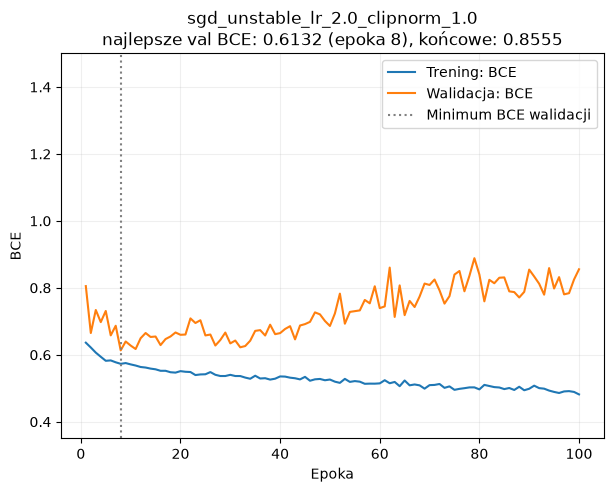

In [67]:
# run_experiment(ExperimentConfig(name="sgd_baseline_unstable", early_stopping=False, momentum=0.0, l2=0.0, dropout=0), X_train_s=X_train_s, y_train=y_train, X_val_s=X_val_s, y_val=y_val)

# plot_history("sgd_baseline_unstable")

# for lr in [0.1, 0.5, 1.0, 2.0, 5.0]:
#     run_experiment(ExperimentConfig(name=f"sgd_baseline_unstable_{lr}", early_stopping=False, momentum=0.0, l2=0.0, dropout=0, learning_rate=lr), X_train_s=X_train_s, y_train=y_train, X_val_s=X_val_s, y_val=y_val)

# plot_compare(["sgd_momentum_overfit", "sgd_dropout"], metric="val_bce", filename="compare_sgd_momentum_overfit&sgd_dropout.png")

run_experiment(ExperimentConfig(name="sgd_unstable_lr_2.0_clipnorm_1.0", early_stopping=False, l2=0.0, dropout=0, learning_rate=2.0, clipnorm=1.0), X_train_s=X_train_s, y_train=y_train, X_val_s=X_val_s, y_val=y_val)

plot_history("sgd_unstable_lr_2.0_clipnorm_1.0", ylim=(0.35, 1.5))


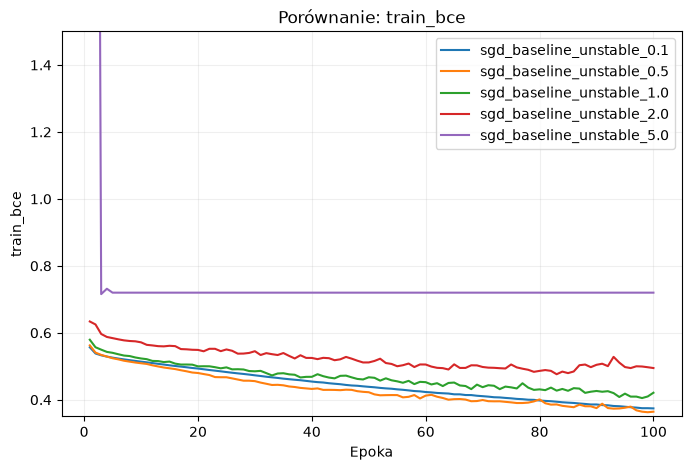

In [59]:
plot_compare(["sgd_baseline_unstable_0.1", "sgd_baseline_unstable_0.5", "sgd_baseline_unstable_1.0", "sgd_baseline_unstable_2.0", "sgd_baseline_unstable_5.0"], metric="train_bce", filename="compare_unstable_lr_training.png", ylim=(0.35, 1.5))

In [78]:
# problem2 = ["baselineSGD", "sgd_baseline_unstable_2.0",  "sgd_unstable_lr_2.0_reduce_lr_on_plateau", "sgd_unstable_lr_2.0_clipnorm_1.0", "sgd_baseline_unstable_5.0", "sgd_unstable_lr_5.0_clipnorm_1.0",  "sgd_unstable_lr_5.0_reduce_lr_on_plateau"]
# table = results_table(problem2)
# (RESULTS_DIR / "problem2_results.md").write_text(table, encoding="utf-8")
# display(Markdown(results_table(problem2)))
# # 

logreg = LogisticRegression(max_iter=1000, random_state=2026)
logreg.fit(X_train_s, y_train)
logreg_pred = logreg.predict(X_val_s)
print("Logistic Regression Validation Accuracy:", accuracy_score(y_val, logreg_pred))

final_config = ExperimentConfig(name="final", momentum=0.9, dropout=0.5)
final_model, final_rows, final_summary = run_experiment(final_config, X_train_s, y_train, X_val_s, y_val)

y_test_flat = y_test.ravel()

nn_pred = (final_model.predict(X_test_s, verbose=0).ravel() >= 0.5).astype(int)

logreg_test_pred = logreg.predict(X_test_s)
majority = int(np.bincount(y_train.ravel().astype(int)).argmax())
dummy_test_pred = np.full(len(y_test_flat), majority)

test_results = {
    "Zawsze częstsza klasa": evaluate(y_test_flat, dummy_test_pred),
    "Regresja logistyczna": evaluate(y_test_flat, logreg_test_pred),
    "Sieć (model końcowy)": evaluate(y_test_flat, nn_pred),
}
for name, m in test_results.items():
    print(f"{name:25} " + "  ".join(f"{k}: {v:.3f}" for k, v in m.items()))


c:\Users\mrvip\Documents\Projekty\Projekt1\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Logistic Regression Validation Accuracy: 0.7408906882591093
Zawsze częstsza klasa     accuracy: 0.501  precision: 0.000  recall: 0.000  f1: 0.000
Regresja logistyczna      accuracy: 0.718  precision: 0.711  recall: 0.732  f1: 0.722
Sieć (model końcowy)      accuracy: 0.715  precision: 0.720  recall: 0.703  f1: 0.711


c:\Users\mrvip\Documents\Projekty\Projekt1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


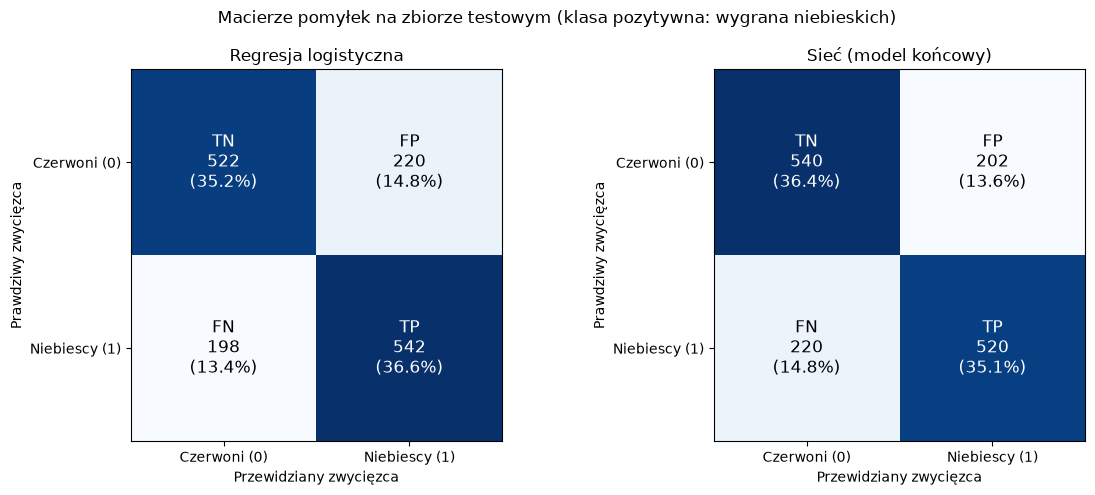

In [81]:
def plot_confusion(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)         
    names = [["TN", "FP"], ["FN", "TP"]]
    total = cm.sum()

    ax.imshow(cm, cmap="Blues")
    for i in range(2):     
        for j in range(2):    
            value = cm[i, j]
            color = "white" if value > cm.max() / 2 else "black"
            ax.text(j, i, f"{names[i][j]}\n{value}\n({value / total:.1%})",
                    ha="center", va="center", fontsize=12, color=color)

    ax.set_xticks([0, 1], labels=["Czerwoni (0)", "Niebiescy (1)"])
    ax.set_yticks([0, 1], labels=["Czerwoni (0)", "Niebiescy (1)"])
    ax.set_xlabel("Przewidziany zwycięzca")
    ax.set_ylabel("Prawdziwy zwycięzca")
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_confusion(axes[0], y_test_flat, logreg_test_pred, "Regresja logistyczna")
plot_confusion(axes[1], y_test_flat, nn_pred, "Sieć (model końcowy)")
fig.suptitle("Macierze pomyłek na zbiorze testowym (klasa pozytywna: wygrana niebieskich)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "p7_macierze_pomylek.png", dpi=150, bbox_inches="tight")
plt.show()

| eksperyment | best_val_bce | best_epoch | last_epoch_val_bce | epochs_run |
| --- | --- | --- | --- | --- |
| sgd_momentum_overfit | 0.5618 | 8 | 0.8874 | 100 |
| sgd_l2_0.0001 | 0.5607 | 8 | 0.9227 | 100 |
| sgd_l2_0.001 | 0.5482 | 10 | 0.6719 | 100 |
| sgd_l2_0.01 | 0.5430 | 3 | 0.5684 | 100 |

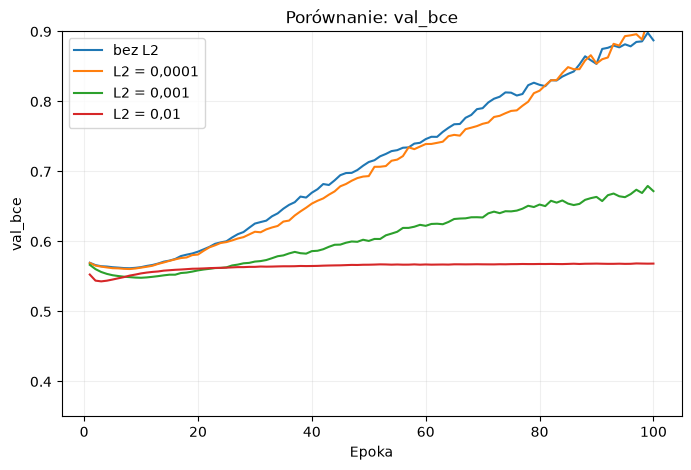

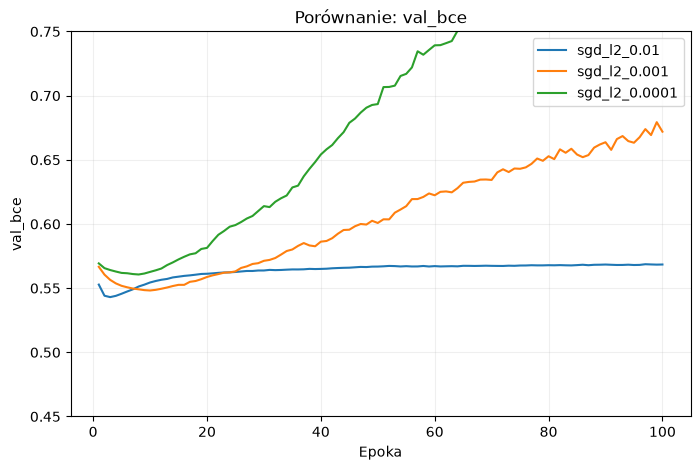

In [88]:
overfit = ExperimentConfig(name="sgd_momentum_overfit", momentum=0.9)
run_experiment(overfit, X_train_s, y_train, X_val_s, y_val)
for l2 in [0.0001, 0.001, 0.01]:
    run_experiment(replace(overfit, name=f"sgd_l2_{l2}", l2=l2), X_train_s, y_train, X_val_s, y_val)

l2_names = ["sgd_momentum_overfit", "sgd_l2_0.0001", "sgd_l2_0.001", "sgd_l2_0.01"]
display(Markdown(results_table(l2_names)))
plot_compare(l2_names, metric="val_bce", labels=["bez L2", "L2 = 0,0001", "L2 = 0,001", "L2 = 0,01"],
             ylim=(0.35, 0.9), filename="p6_l2_val_bce.png")

plot_compare(["sgd_l2_0.01", "sgd_l2_0.001", "sgd_l2_0.0001"], metric="val_bce", filename="compare_sgd_l2.png")


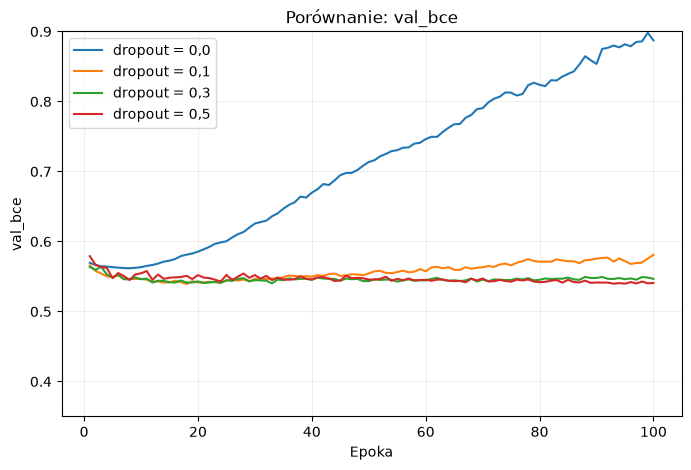

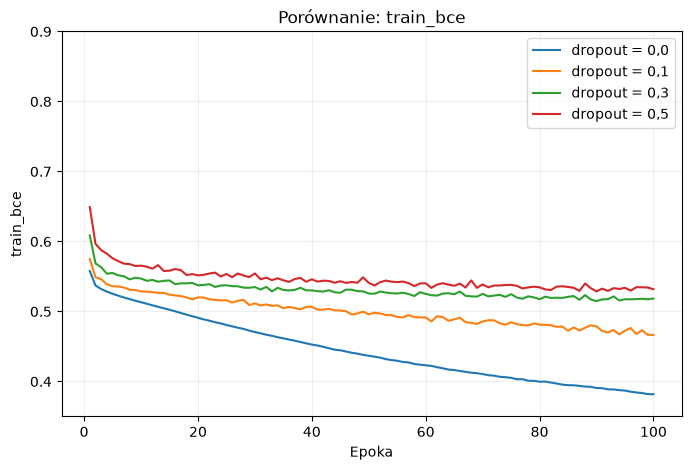

| eksperyment | best_val_bce | best_epoch | last_epoch_val_bce | best_val_accuracy |
| --- | --- | --- | --- | --- |
| p6_dropout_0.0 | 0.5618 | 8 | 0.8874 | 0.7146 |
| p6_dropout_0.1 | 0.5394 | 18 | 0.5810 | 0.7186 |
| p6_dropout_0.3 | 0.5402 | 33 | 0.5466 | 0.7281 |
| p6_dropout_0.5 | 0.5398 | 93 | 0.5407 | 0.7260 |

In [89]:
overfit = ExperimentConfig(name="sgd_momentum_overfit", momentum=0.9)

p6_names, p6_labels = [], []
for p in [0.0, 0.1, 0.3, 0.5]:
    name = f"p6_dropout_{p}"
    run_experiment(replace(overfit, name=name, dropout=p), X_train_s, y_train, X_val_s, y_val)
    p6_names.append(name)
    p6_labels.append(f"dropout = {p:.1f}".replace(".", ","))

plot_compare(p6_names, metric="val_bce", labels=p6_labels, ylim=(0.35, 0.9), filename="p6_dropout_val_bce.png")
plot_compare(p6_names, metric="train_bce", labels=p6_labels, ylim=(0.35, 0.9), filename="p6_dropout_train_bce.png")

table = results_table(p6_names, columns=("best_val_bce", "best_epoch", "last_epoch_val_bce", "best_val_accuracy"))
(RESULTS_DIR / "p6_dropout_tabela.md").write_text(table, encoding="utf-8")
display(Markdown(table))